In [1]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.ticker import FuncFormatter
from io import StringIO
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

from scipy.stats import linregress

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


In [2]:
mpl.rcParams['figure.dpi'] = 500

## Carga de datos

In [5]:
scenarios = ["B0-05-d", "B1-1-d", "B1-1-h", "B1-1-mc", "B2-60-d"]
shocks = ["RS", "FS"]

In [6]:
read = {
    "syn": "radsyn",
    "IC_star": "radic_st", 
    "IC_IR": "radic_ir",
    "br": "radbr",
    "pp": "radpp",
}

In [7]:
data = {}

for sc in scenarios:
    data[sc] = {}
    
    for shock in shocks:
        data[sc][shock] = {}

        files = {
            "syn": f"../../../radsyn_{sc}_{shock}_tot.dat",
            "IC_star": f"../../../radic_st_{sc}_{shock}_tot.dat",
            "IC_IR": f"../../../radic_ir_{sc}_{shock}_tot.dat",
            "br": f"../../../radbr_{sc}_{shock}_tot.dat",
            "pp": f"../../../radpp_{sc}_{shock}_tot.dat",
        }

        # =========================
        # Lectura común
        # =========================
        for key, archivo in files.items():

            if not os.path.exists(archivo):
                print(f"Missing file: {archivo}")
                continue

            try:
                archivo_data = leer_archivo(archivo)

                if len(archivo_data) == 0:
                    print(f"Empty file: {archivo}")
                    continue

                data[sc][shock][f"E_{key}"] = archivo_data[:, 0].copy()
                data[sc][shock][key]       = archivo_data[:, 1].copy()

            except Exception as e:
                print(f"Reading error {archivo}: {e}")

# Sensitivity curves

In [9]:
file_fermi = 'sens_fermi10yr_0_0.dat'
df_fermi = pd.read_csv(file_fermi, delim_whitespace=True, skiprows=2)

E_fermi = df_fermi.iloc[:,0]*1e6
sens_fermi = df_fermi.iloc[:,1]*factor_distance

In [10]:
file_CTA = 'sens_CTA_50h.dat'
df_CTA = pd.read_csv(file_CTA, delim_whitespace=True, skiprows=2)

E_CTA = df_CTA.iloc[:,0]
sens_CTA = df_CTA.iloc[:,1]*factor_distance

In [11]:
file_LHAASO = 'sens_LHAASO.dat'
df_LHAASO = pd.read_csv(file_LHAASO, delim_whitespace=True, skiprows=2)

E_LHAASO = df_LHAASO.iloc[:,0]
sens_LHAASO = df_LHAASO.iloc[:,1]*factor_distance

In [12]:
file_VLA = 'sens_VLA.dat'
df_VLA = pd.read_csv(file_VLA, delim_whitespace=True)

freq_VLA = df_VLA.iloc[:,0]*1e9
E_VLA = (h*freq_VLA)/eV
sens_VLA = df_VLA.iloc[:,1]
sens_VLA = 1e-6*Jy*sens_VLA*freq_VLA * factor_distance

In [13]:
file_ngVLA = 'sens_ngVLA.dat'
df_ngVLA = pd.read_csv(file_ngVLA, delim_whitespace=True)

freq_ngVLA = df_ngVLA.iloc[:,0]*1e9
E_ngVLA = (h*freq_ngVLA)/eV
sens_ngVLA = df_ngVLA.iloc[:,1]/np.sqrt(2.)
sens_ngVLA = 1e-6*Jy*sens_ngVLA*freq_ngVLA * factor_distance

In [14]:
file_SKA = 'sens_SKA.dat'
df_SKA = pd.read_csv(file_SKA, delim_whitespace=True)

freq_SKA = df_SKA.iloc[:,0]*1e9
E_SKA = (h*freq_SKA)/eV
sens_SKA = df_SKA.iloc[:,1]/np.sqrt(2.)
sens_SKA = 1e-6*Jy*sens_SKA*freq_SKA * factor_distance

In [15]:
file_chandra = 'sens_chandra.dat'
df_chandra = pd.read_csv(file_chandra, delim_whitespace=True)

E_chandra = df_chandra.iloc[:, 0]*1e3
sens_chandra = df_chandra.iloc[:, 1]*factor_distance

# Total SED

In [16]:
sed_tot = {}

for sc in scenarios:

    components = [
        ("E_syn", "syn"),
        ("E_IC_star", "IC_star"),
        ("E_IC_IR", "IC_IR"),
        ("E_br", "br"),
        ("E_pp", "pp")
    ]

    E_min = min(
        data[sc][shock][E_key].min()
        for shock in shocks
        for E_key, _ in components
    )

    E_max = max(
        data[sc][shock][E_key].max()
        for shock in shocks
        for E_key, _ in components
    )

    E_tot = np.geomspace(E_min, E_max, 400)

    L_tot = np.zeros_like(E_tot)

    for shock in shocks:
        for E_key, L_key in components:
            L_tot += np.interp(
                E_tot,
                data[sc][shock][E_key],
                data[sc][shock][L_key],
                left=0,
                right=0
            )

    sed_tot[sc] = {
        "E_tot": E_tot,
        "L_tot": L_tot
    }

## Creación de la gráfica

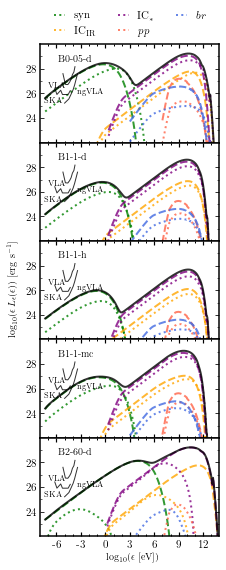

In [21]:
fig, ax = plt.subplots(
    5, 1,
    figsize=(0.6*text_width, 5.*1.2*0.7*text_width/3.),
    sharex=True,
    sharey=True
)

for i, sc in enumerate(scenarios):

    axi = ax[i]
    d = sed_tot[sc]

    axi.plot(
        safe_log10(data[sc]["RS"]["E_syn"]),
        safe_log10(data[sc]["RS"]["syn"]),
        color="green", ls=":", lw=2, alpha=0.8,
        label=r"syn"
    )

    axi.plot(
        safe_log10(data[sc]["FS"]["E_syn"]),
        safe_log10(data[sc]["FS"]["syn"]),
        color="green", ls="--", lw=2, alpha=0.8
    )

    axi.plot(
        safe_log10(data[sc]["RS"]["E_IC_IR"]),
        safe_log10(data[sc]["RS"]["IC_IR"]),
        color="orange", ls=":", lw=2, alpha=0.8,
        label=r"IC$_{\rm IR}$"
    )

    axi.plot(
        safe_log10(data[sc]["FS"]["E_IC_IR"]),
        safe_log10(data[sc]["FS"]["IC_IR"]),
        color="orange", ls="--", lw=2, alpha=0.8
    )

    axi.plot(
        safe_log10(data[sc]["RS"]["E_IC_star"]),
        safe_log10(data[sc]["RS"]["IC_star"]),
        color="purple", ls=":", lw=2, alpha=0.8,
        label=r"IC$_*$"
    )

    axi.plot(
        safe_log10(data[sc]["FS"]["E_IC_star"]),
        safe_log10(data[sc]["FS"]["IC_star"]),
        color="purple", ls="--", lw=2, alpha=0.8
    )

    axi.plot(
        safe_log10(data[sc]["RS"]["E_pp"]),
        safe_log10(data[sc]["RS"]["pp"]),
        color="tomato", ls=":", lw=2, alpha=0.8,
        label=r"$pp$"
    )

    axi.plot(
        safe_log10(data[sc]["FS"]["E_pp"]),
        safe_log10(data[sc]["FS"]["pp"]),
        color="tomato", ls="--", lw=2, alpha=0.8
    )

    axi.plot(
        safe_log10(data[sc]["RS"]["E_br"]),
        safe_log10(data[sc]["RS"]["br"]),
        color="royalblue", ls=":", lw=2, alpha=0.8,
        label=r"$br$"
    )

    axi.plot(
        safe_log10(data[sc]["FS"]["E_br"]),
        safe_log10(data[sc]["FS"]["br"]),
        color="royalblue", ls="--", lw=2, alpha=0.8
    )

    # ===== Total SED =====
    axi.plot(
        safe_log10(d["E_tot"]),
        safe_log10(d["L_tot"]),
        color="black", lw=2, alpha=0.8
    )
    
    # Instruments
    # VLA label
    axi.plot(np.log10(E_VLA), np.log10(sens_VLA),
             label = '', color = 'black', alpha=0.8, linewidth = 1.)
    axi.text(-7., 26.5, "VLA", fontsize=8)

    # ngVLA label
    axi.plot(np.log10(E_ngVLA), np.log10(sens_ngVLA),
             label = '', color = 'black', alpha=0.8, linewidth = 1.)
    axi.text(-3.5, 26., "ngVLA", fontsize=8)

    # SKA label
    axi.plot(np.log10(E_SKA), np.log10(sens_SKA), 
             label = '', color = 'black', alpha=0.8, linewidth = 1.)
    axi.text(-7.5, 25.25, "SKA", fontsize=8)
    
     # Chandra label
    #axi.plot(np.log10(E_chandra), np.log10(sens_chandra), 
    #         label = '', color = 'black', alpha=0.8, linewidth = 1.)
    #axi.text(4, 29, r"$Chandra$", fontsize=8)
    
    axi.set_xlim(-8, 14)
    ticks_x = [-6, -3, 0, 3, 6, 9, 12]
    axi.set_xticks(ticks_x)
    axi.set_xticklabels([f"{int(t)}" for t in ticks_x])
    minor_ticks_x = [-7, -5, -4, -2, -1, 1, 2, 4, 5, 7, 8, 10, 11, 13]
    axi.set_xticks(minor_ticks_x, minor=True)
    
    axi.set_ylim(22, 30)
    ticks_y = [24, 26, 28]
    axi.set_yticks(ticks_y)
    axi.set_yticklabels([f"{int(t)}" for t in ticks_y])
    ticks_y_minor = [23, 25, 27, 29]
    
    axi.set_yticks(ticks_y_minor, minor=True)

    axi.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True
    )

    axi.annotate(
        f"{sc}",
        xy=(0.1, 0.90),
        xycoords="axes fraction",
        ha="left",
        va="top"
    )

    axi.xaxis.set_minor_formatter(NullFormatter())
    axi.yaxis.set_minor_formatter(NullFormatter())

# ===== Global labels =====
sp = fig.subplotpars
xmid = (sp.left + sp.right) / 2
ymid = (sp.bottom + sp.top) / 2

fig.text(
    sp.left - 0.07, ymid,
    r"$\log_{10}(\epsilon\,L_\epsilon(\epsilon))$ [erg s$^{-1}$]",
    rotation="vertical",
    ha="center",
    va="center"
)

fig.text(
    xmid, sp.bottom - 0.06,
    r"$\log_{10}(\epsilon$ [eV]$)$",
    ha="center",
    va="center"
)

handles_all = []
labels_all = []

for axi in ax:
    h, l = axi.get_legend_handles_labels()
    for hi, li in zip(h, l):
        if li and li not in labels_all:
            handles_all.append(hi)
            labels_all.append(li)

fig.legend(
    handles_all,
    labels_all,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=3,
    frameon=False,
    handlelength=1.
)

fig.subplots_adjust(
    left=0.16,
    right=0.84,
    bottom=0.10,
    top=0.90,
    hspace=0.0
)

plt.show()

In [22]:
#fig.savefig('SED_HVSs.pdf', bbox_inches='tight', pad_inches = 0.01)